In [1]:
import pandas as pd
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from IPython.display import display


In [2]:
base_dir = Path.cwd()
REPORTS_PATH = base_dir / "output"
SAMPLE_REPORT_PATH = REPORTS_PATH / "sample_report.csv"
SAMPLE_REPORT_PATH
FIGSIZE = (8, 4) # (max(8, len(datasets_sorted) * 1.4), 6)
FONTSIZE = 9
FONTSIZE_SM = 8

In [3]:
df = pd.read_csv(SAMPLE_REPORT_PATH)

df.head()

,Sample name,Dataset name,Subtype,Data silo,GEX data split,DNAm data split,RNA-seq batch
0,AML_046,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,train,NaN
1,AML_059,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,train,NaN
2,AML_075,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,train,NaN
3,AML_106,Krali-2021,"AML, APL-PML::RARA",labeled_diagnostic,NaN,calibrate,NaN
4,SJAML030233_D1,SJC-DS-1009,"AML, APL-PML::RARA",labeled_diagnostic,train,NaN,Total


In [4]:
# Show distribution by dataset
agg = (df.groupby("Dataset name")["Dataset name"]
    .count()
    .rename("count")
    .reset_index()
)
agg

,Dataset name,count
0,Diedrich-2021,19
1,Enblad-2025,55
2,Krali-2021,142
3,Krali-2023,1338
4,Lilljebjorn-2016,195
5,SJC-DS-1009,2625
6,SJC-panALL,1988
7,Safavi-2015,4
8,Stratmann-2022,143
9,TARGET-AML,2183


In [5]:
# ── Color constants (easy to change) ──────────────────────────────────────────
COLOR_GEX     = "#ae62de"   # GEX data split
COLOR_DNAM    = "#CE61A6"   # DNAm data split
COLOR_DUALMODAL = "#D46059"   # Dual-modal

COLOR_LABELED_DIAGNOSTIC = "#5C86E0"  # labeled_diagnostic
COLOR_UNLABELED = "#51a9d5"
COLOR_RELAPSE   = "#67c288"
COLOR_REPLICATE = "#9bbc4f"
COLOR_MULTICLASS= "#ddcc47"
COLOR_UNRECOG   = "#D28844"   # excluded/unrecognised (light gray)

BAR_EDGE      = "white"
BAR_WIDTH     = 0.65
FIG_BG        = "#F8F9FB"
AXES_BG       = "#FFFFFF"


In [6]:
# ── Aggregate ──────────────────────────────────────────────────────────────────
agg_by_silo = (
    df.groupby("Dataset name")
    .agg(
        total = ("Sample name", "count"),
        n_labeled_diagnostic = (
            "Data silo",
            lambda s: s.eq("labeled_diagnostic").sum(),
        ),
        # counts for requested Data silo values (explicit categories)
        n_unlabeled = (
            "Data silo",
            lambda s: s.eq("unlabeled").sum(),
        ),
        n_relapse = (
            "Data silo",
            lambda s: s.eq("relapse").sum(),
        ),
        n_replicate = (
            "Data silo",
            lambda s: s.eq("replicate").sum(),
        ),
        n_multiclass = (
            "Data silo",
            lambda s: s.eq("multiclass").sum(),
        ),
        n_excluded_or_unrecognised = (
            "Data silo",
            lambda s: s.isin(["excluded", "unrecognised"]).sum(),
        ),
    )
    .sort_values("total", ascending=False)
    .reset_index()
)

agg_by_silo


,Dataset name,total,n_labeled_diagnostic,n_unlabeled,n_relapse,n_replicate,n_multiclass,n_excluded_or_unrecognised
0,SJC-DS-1009,2625,970,322,115,742,72,98
1,TARGET-AML,2183,1411,231,300,131,27,21
2,SJC-panALL,1988,1662,125,0,0,88,76
3,Krali-2023,1338,1176,106,32,8,0,16
4,Lilljebjorn-2016,195,174,21,0,0,0,0
5,Tran-2022,173,146,16,0,0,11,0
6,Stratmann-2022,143,41,33,45,0,12,0
7,Krali-2021,142,69,41,0,0,0,1
8,TCGA-LAML,79,75,0,0,0,0,4
9,Enblad-2025,55,27,28,0,0,0,0


In [7]:

# ── Aggregate ──────────────────────────────────────────────────────────────────
agg_by_modality = (
    df.groupby("Dataset name")
    .agg(
        total = ("Sample name", "count"),
        # also keep exclusive counts (only present in one split)
        n_labeled_diagnostic = (
            "Data silo",
            lambda s: s.eq("labeled_diagnostic").sum(),
        ),
        n_gex_only = (
            "Sample name",
            lambda s: sum(
                df.loc[s.index, "Data silo"].eq("labeled_diagnostic") &
                ~df.loc[s.index, "GEX data split"].isna() &
                df.loc[s.index, "DNAm data split"].isna()
            ),
        ),
        n_dnam_only = (
            "Sample name",
            lambda s: sum(
                df.loc[s.index, "Data silo"].eq("labeled_diagnostic") &
                df.loc[s.index, "GEX data split"].isna() &
                ~df.loc[s.index, "DNAm data split"].isna()
            ),
        ),
        n_dualmodal = (
            "Sample name",
            lambda s: sum(
                df.loc[s.index, "Data silo"].eq("labeled_diagnostic") &
                ~df.loc[s.index, "GEX data split"].isna() &
                ~df.loc[s.index, "DNAm data split"].isna()
            ),
        ),
    )
    .sort_values("n_labeled_diagnostic", ascending=False)
    .reset_index()
)

agg_by_modality


,Dataset name,total,n_labeled_diagnostic,n_gex_only,n_dnam_only,n_dualmodal
0,SJC-panALL,1988,1662,1662,0,0
1,TARGET-AML,2183,1411,274,282,855
2,Krali-2023,1338,1176,75,812,288
3,SJC-DS-1009,2625,970,970,0,0
4,Lilljebjorn-2016,195,174,174,0,0
5,Tran-2022,173,146,146,0,0
6,TCGA-LAML,79,75,2,19,54
7,Krali-2021,142,69,0,69,0
8,Stratmann-2022,143,41,2,0,39
9,Enblad-2025,55,27,0,27,0


In [8]:
# Sort datasets by total number of samples descending
datasets_sorted = agg_by_silo.sort_values("total", ascending=False)["Dataset name"].tolist()
x = np.arange(len(datasets_sorted))
datasets_sorted, x


(['SJC-DS-1009',
  'TARGET-AML',
  'SJC-panALL',
  'Krali-2023',
  'Lilljebjorn-2016',
  'Tran-2022',
  'Stratmann-2022',
  'Krali-2021',
  'TCGA-LAML',
  'Enblad-2025',
  'Diedrich-2021',
  'Safavi-2015'],
 array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]))

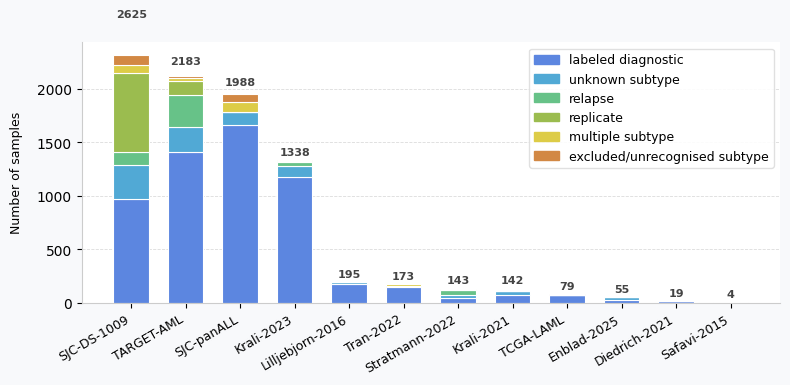

In [9]:


# ── Plot 1: labeled diagnostic vs excluded ────────────────────────────────────
fig1, ax = plt.subplots(figsize=FIGSIZE)
fig1.patch.set_facecolor(FIG_BG)
ax.set_facecolor(AXES_BG)

ax.bar(
    x,
    agg_by_silo["n_labeled_diagnostic"],
    width=BAR_WIDTH,
    color=COLOR_LABELED_DIAGNOSTIC,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    label="labeled diagnostic",
)
ax.bar(
    x,
    agg_by_silo["n_unlabeled"],
    width=BAR_WIDTH,
    color=COLOR_UNLABELED,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg_by_silo["n_labeled_diagnostic"],
    label="unknown subtype",
)
# Add bar for relapse, replicate, multiclass, and unlabeled categories (stacked on top of labeled_diagnostic)
ax.bar(
    x,
    agg_by_silo["n_relapse"],
    width=BAR_WIDTH,
    color=COLOR_RELAPSE,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg_by_silo["n_labeled_diagnostic"] + agg_by_silo["n_unlabeled"],
    label="relapse samples",
)
ax.bar(
    x,
    agg_by_silo["n_replicate"],
    width=BAR_WIDTH,
    color=COLOR_REPLICATE,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg_by_silo["n_labeled_diagnostic"] + agg_by_silo["n_unlabeled"]+ agg_by_silo["n_relapse"],
    label="replicate samples",
)
ax.bar(
    x,
    agg_by_silo["n_multiclass"],
    width=BAR_WIDTH,
    color=COLOR_MULTICLASS,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg_by_silo["n_labeled_diagnostic"] + agg_by_silo["n_unlabeled"] + agg_by_silo["n_relapse"] + agg_by_silo["n_replicate"],
    label="multiple subtype",
)
ax.bar(
    x,
    agg_by_silo["n_excluded_or_unrecognised"],
    width=BAR_WIDTH,
    color=COLOR_UNRECOG,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg_by_silo["n_labeled_diagnostic"] + agg_by_silo["n_unlabeled"] + agg_by_silo["n_relapse"] + agg_by_silo["n_replicate"] + agg_by_silo["n_multiclass"],
    label="excluded/unrecognised subtype",
)

for i, row in agg_by_silo.iterrows():
    ax.text(
        x[i], row["total"] + agg_by_silo["total"].max() * 0.01,
        int(row["total"]),
        #f'{int(row["n_labeled_diagnostic"])}/{int(row["total"])}',
        ha="center", va="bottom",
        fontsize=FONTSIZE_SM, fontweight="bold", color="#444444",
    )

ax.set_xticks(x)
ax.set_xticklabels(datasets_sorted, rotation=30, ha="right", fontsize=FONTSIZE)
ax.set_ylabel("Number of samples", fontsize=FONTSIZE, labelpad=10)
# title removed per request
ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.7, color="#CCCCCC")
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#CCCCCC")

ax.legend(
    handles=[
        mpatches.Patch(color=COLOR_LABELED_DIAGNOSTIC, label="labeled diagnostic"),
        mpatches.Patch(color=COLOR_UNLABELED, label="unknown subtype"),
        mpatches.Patch(color=COLOR_RELAPSE, label="relapse"),
        mpatches.Patch(color=COLOR_REPLICATE, label="replicate"),
        mpatches.Patch(color=COLOR_MULTICLASS, label="multiple subtype"),
        mpatches.Patch(color=COLOR_UNRECOG, label="excluded/unrecognised subtype"),
    ],
    loc="upper right",
    frameon=True,
    framealpha=0.9,
    edgecolor="#DDDDDD",
    fontsize=FONTSIZE,
)

plt.tight_layout()
plt.savefig(str(REPORTS_PATH / "dataset_by_silo.svg"), format="svg", dpi=150, bbox_inches="tight")
display(fig1)
plt.close(fig1)


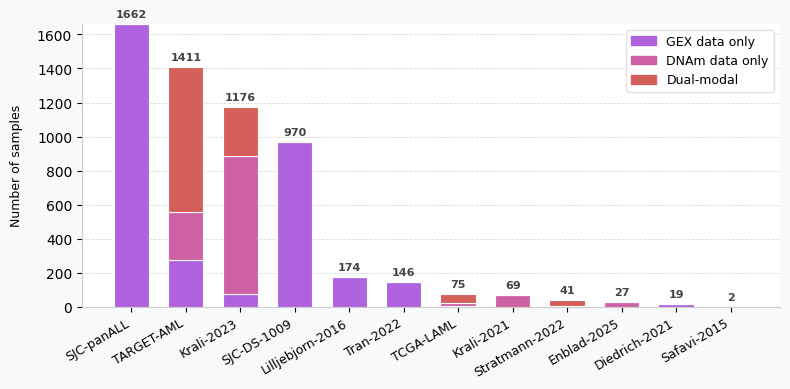

Charts saved to /home/mariya/Development/pallas/reports/output/dataset_by_modality.svg


In [10]:

# ── Plot 2: split categories without excluded samples ──────────────────────────
datasets_sorted = agg_by_modality["Dataset name"].tolist()
x = np.arange(len(datasets_sorted))

fig2, ax = plt.subplots(figsize=FIGSIZE)
fig2.patch.set_facecolor(FIG_BG)
ax.set_facecolor(AXES_BG)

ax.bar(
    x,
    agg_by_modality["n_gex_only"],
    width=BAR_WIDTH,
    color=COLOR_GEX,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    label="GEX data split only",
)
ax.bar(
    x,
    agg_by_modality["n_dnam_only"],
    width=BAR_WIDTH,
    color=COLOR_DNAM,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg_by_modality["n_gex_only"],
    label="DNAm data split only",
)
ax.bar(
    x,
    agg_by_modality["n_dualmodal"],
    width=BAR_WIDTH,
    color=COLOR_DUALMODAL,
    edgecolor=BAR_EDGE,
    linewidth=0.8,
    bottom=agg_by_modality["n_gex_only"] + agg_by_modality["n_dnam_only"],
    label="Dual-modal",
)

for i, row in agg_by_modality.iterrows():
    ax.text(
        x[i], row["n_labeled_diagnostic"] + agg_by_modality["total"].max() * 0.01,
        str(int(row["n_labeled_diagnostic"])),
        ha="center", va="bottom",
        fontsize=FONTSIZE_SM, fontweight="bold", color="#444444",
    )

ax.set_xticks(x)
ax.set_xticklabels(datasets_sorted, rotation=30, ha="right", fontsize=FONTSIZE)
ax.set_ylabel("Number of samples", fontsize=FONTSIZE, labelpad=10)
# title removed per request
ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.7, color="#CCCCCC")
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#CCCCCC")

ax.legend(
    handles=[
        mpatches.Patch(color=COLOR_GEX, label="GEX data only"),
        mpatches.Patch(color=COLOR_DNAM, label="DNAm data only"),
        mpatches.Patch(color=COLOR_DUALMODAL, label="Dual-modal"),
    ],
    loc="upper right",
    frameon=True,
    framealpha=0.9,
    edgecolor="#DDDDDD",
    fontsize=FONTSIZE,
)

plt.tight_layout()
plt.savefig(str(REPORTS_PATH / "dataset_by_modality.svg"), format="svg", dpi=150, bbox_inches="tight")
display(fig2)
plt.close(fig2)
print(f"Charts saved to {REPORTS_PATH / 'dataset_by_modality.svg'}")
